# Лабораторная работа 2
> - **Предмет:** МОСИИ
> - **Студент:** Руденко Андрей Артемович
> - **Группа:** М9125-01.04.02МКТ

**Цель работы:** Реализация и сравнение модификаций градиентного спуска.

In [1]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

## Генерация выборки

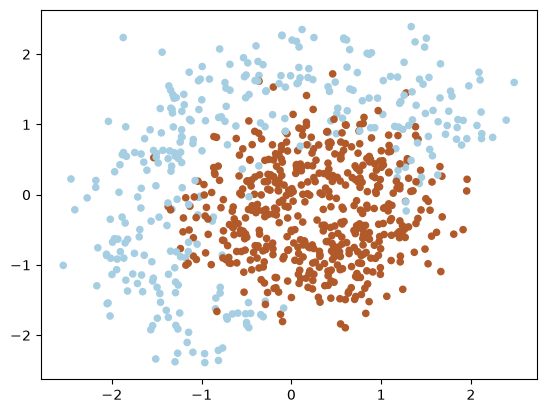

In [2]:
from sklearn import datasets, preprocessing

# keep random_state=42 for deterministic results
(X, y) = datasets.make_circles(n_samples=1024, shuffle=True, noise=0.2, factor=0.4, random_state=42)
ind = np.logical_or(y == 1, X[:, 1] > X[:, 0] - 0.5)
X = X[ind, :]
m = np.array([[1, 1], [-2, 1]])
X = preprocessing.scale(X)
y = y[ind]

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, s=20)
plt.show()

## Добавление признаков

Данные не являются линейно разделимыми: один класс внутри, другой вокруг. Предполагаем, что разделяющая поверхность имеет вид окружности, поэтому добавляем колонки $x_1^2$, $x_2^2$, $x_1 \cdot x_2$ и единицу для свободного члена.

In [3]:
def expand(X):
    """
    Добавляет квадратичные фичи.
    Для каждой строки матрицы находит строку
    [feature0, feature1, feature0^2, feature1^2, feature0*feature1, 1]

    :param X: матрица фичей, shape [n_samples,2]
    :returns: расширенная матрица фичей, shape [n_samples,6]
    """
    x0, x1 = X[:, 0], X[:, 1]
    return np.column_stack([x0, x1, x0 ** 2, x1 ** 2, x0 * x1, np.ones(X.shape[0])])


X_expanded = expand(X)

## Логистическая регрессия

$$ a(x; w) = \langle w, x \rangle $$
$$ P( y=1 \; \big| \; x, \, w) = \dfrac{1}{1 + \exp(- \langle w, x \rangle)} = \sigma(\langle w, x \rangle)$$

In [4]:
def probability(X, w):
    """
    Возвращает вероятность того, что y = 1 при фиксированных x, P(y=1|x)

    :param X: расширенная матрица фичей [n_samples,6] (expanded)
    :param w: вектор весов [6]
    :returns: вектор вероятностей
    """
    return 1 / (1 + np.exp(-X @ w))


def accuracy(w):
    return np.mean((probability(X_expanded, w) > 0.5) == y)

Функция потерь — кросс-энтропия:

$$ L(w) =  - {1 \over \ell} \sum_{i=1}^\ell \left[ {y_i \cdot log P(y_i = 1 \, | \, x_i,w) + (1-y_i) \cdot log (1-P(y_i = 1 \, | \, x_i,w))}\right] $$

In [5]:
def compute_loss(X, y, w):
    p = probability(X, w)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

Градиент считаем на листочке. Производная сигмоиды $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, поэтому для одного объекта

$$ \dfrac{\partial}{\partial w}\Big[y \log \sigma + (1-y)\log(1-\sigma)\Big] = y(1-\sigma)x - (1-y)\sigma x = (y - \sigma)x $$

С минусом и усреднением:

$$ \nabla_w L = {1 \over \ell} \sum_{i=1}^\ell \big(\sigma(\langle w, x_i \rangle) - y_i\big) x_i $$

In [6]:
def compute_grad(X, y, w):
    return X.T @ (probability(X, w) - y) / len(y)

Функция для визуализации обучения: слева разделяющая поверхность, справа loss по итерациям.

In [7]:
from IPython import display

h = 0.01
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

def visualize(X, y, w, history):
    """С помощью магии matplolib выдаёт красоты результатов классификации"""
    Z = probability(expand(np.c_[xx.ravel(), yy.ravel()]), w)
    Z = Z.reshape(xx.shape)
    plt.subplot(1, 2, 1)
    plt.contourf(xx, yy, Z, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

    plt.subplot(1, 2, 2)
    plt.plot(history)
    plt.grid()
    ymin, ymax = plt.ylim()
    plt.ylim(0, ymax)
    display.clear_output(wait=True)
    plt.show()

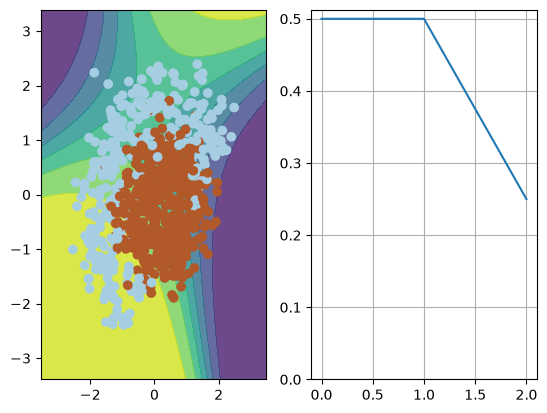

In [8]:
# проверка, что expand и probability работают
dummy_weights = np.linspace(-1, 1, 6)
visualize(X, y, dummy_weights, [0.5, 0.5, 0.25])

## Обучение

Все методы запускаем с одинаковым `np.random.seed(42)`, поэтому батчи у них одни и те же и сравнение честное. Loss считаем на всей выборке после каждого шага.

In [9]:
results = {}

## Mini-batch SGD

$$ w_t = w_{t-1} - \eta \dfrac{1}{m} \sum_{j=1}^m \nabla_w L(w_t, x_{i_j}, y_{i_j}) $$

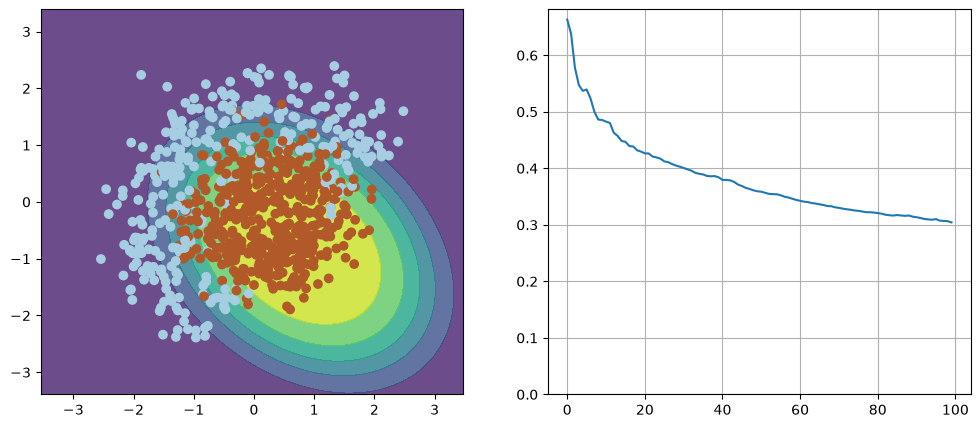

Loss: 0.304, точность: 0.913


<Figure size 640x480 with 0 Axes>

In [10]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    w = w - eta * grad
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['Mini-batch SGD'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

`Обязательно попробуйте поменять гиперпараметры (размер батча и скорость обучения)`

In [11]:
for batch_size in [1, 4, 64]:
    for eta in [0.01, 0.1, 1]:
        np.random.seed(42)
        w = np.array([0, 0, 0, 0, 0, 1.])
        for i in range(100):
            ind = np.random.choice(X.shape[0], batch_size)
            w = w - eta * compute_grad(X_expanded[ind], y[ind], w)
        print(f'batch_size={batch_size}, eta={eta}: loss {compute_loss(X_expanded, y, w):.3f}, точность {accuracy(w):.3f}')

batch_size=1, eta=0.01: loss 0.501, точность 0.803
batch_size=1, eta=0.1: loss 0.307, точность 0.916
batch_size=1, eta=1: loss 0.298, точность 0.875
batch_size=4, eta=0.01: loss 0.492, точность 0.822
batch_size=4, eta=0.1: loss 0.304, точность 0.913
batch_size=4, eta=1: loss 0.227, точность 0.921
batch_size=64, eta=0.01: loss 0.493, точность 0.815
batch_size=64, eta=0.1: loss 0.306, точность 0.913
batch_size=64, eta=1: loss 0.212, точность 0.909


## Вывод работы Mini-batch SGD

SGD с `eta = 0.1` за 100 итераций доходит до loss 0.30, loss падает медленно и равномерно. Сильнее всего влияет скорость обучения: с `eta = 0.01` модель почти не успевает обучиться (loss 0.49–0.50), а с `eta = 1` при батче 4 и 64 loss ниже (0.21–0.23). Но при батче из одной точки с `eta = 1` точность проседает до 0.875, шаги слишком резкие. При `eta = 0.1` размер батча на итоговый loss почти не влияет.

## Momentum SGD

$$ \nu_t = \alpha \nu_{t-1} + \eta\dfrac{1}{m} \sum_{j=1}^m \nabla_w L(w_t, x_{i_j}, y_{i_j}) $$
$$ w_t = w_{t-1} - \nu_t$$

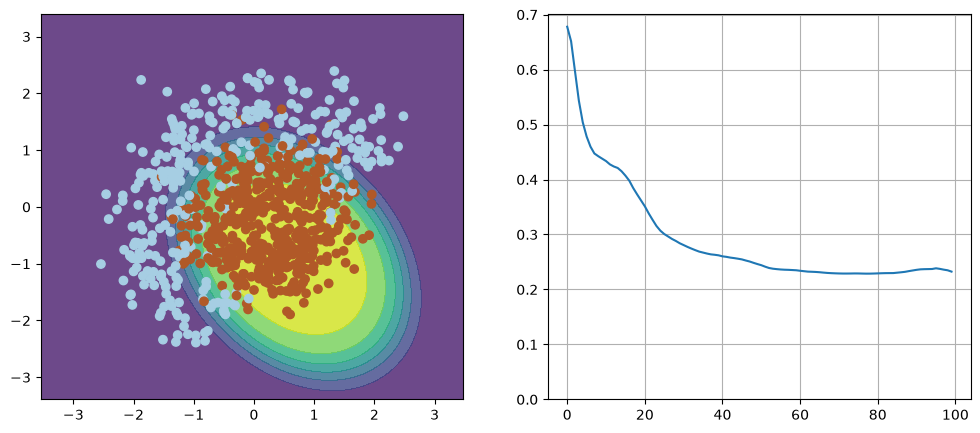

Loss: 0.232, точность: 0.902


<Figure size 640x480 with 0 Axes>

In [12]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.05
alpha = 0.9
nu = np.zeros_like(w)

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    nu = alpha * nu + eta * grad
    w = w - nu
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['Momentum'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы Momentum SGD

Momentum даёт loss 0.23 против 0.30 у SGD, хотя `eta` в два раза меньше. Накопленная скорость сохраняет направление движения, поэтому шум отдельных батчей гасится и спуск идёт быстрее.

## RMSprop

$$ G_t^j = \alpha G_{t-1}^j + (1 - \alpha) g_{tj}^2 $$
$$ w_t^j = w_{t-1}^j - \dfrac{\eta}{\sqrt{G_t^j + \varepsilon}} g_{tj} $$

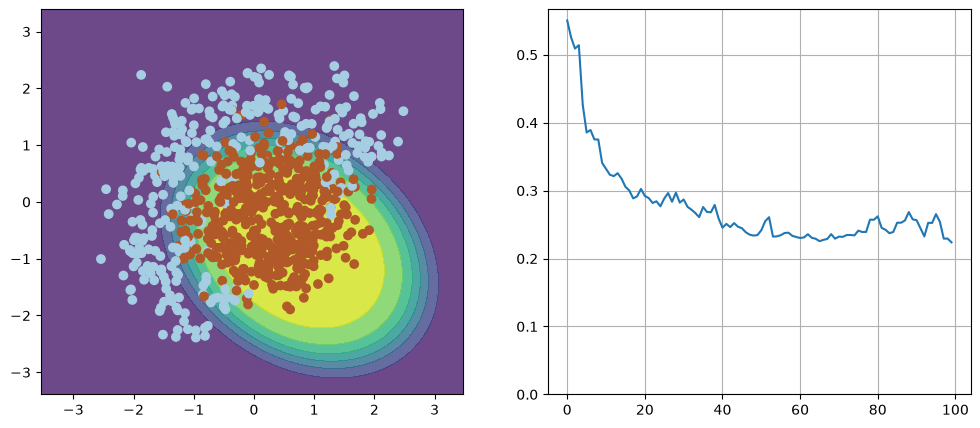

Loss: 0.224, точность: 0.908


<Figure size 640x480 with 0 Axes>

In [13]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1
alpha = 0.9
g2 = np.zeros_like(w)
eps = 1e-8

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    g2 = alpha * g2 + (1 - alpha) * grad ** 2
    w = w - eta / np.sqrt(g2 + eps) * grad
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['RMSprop'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы RMSprop

RMSprop быстрее всех из трёх: уже к 25-й итерации loss около 0.28 (у SGD 0.42), итог 0.22. Шаг делится на средний квадрат градиента, поэтому веса с маленьким градиентом получают шаг больше и не отстают от остальных. Но к концу loss начинает скакать: возле минимума градиент маленький, а шаг на него нормируется и остаётся крупным.

`Как траектории обучения различных вариаций градиентного спуска различаются между собой? Ожидаемо ли это? Почему?`

SGD спускается медленно и ровно. Momentum сначала идёт так же, а потом разгоняется и уходит ниже. RMSprop падает быстрее всех, но к концу скачет. Это ожидаемо: SGD делает маленькие шаги ровно по градиенту, Momentum копит скорость по прошлым шагам, а RMSprop нормирует шаг для каждого веса, поэтому шаг крупный и в начале, и возле минимума.

`Что нужно сделать, чтобы реализовать Adam?`

Объединить Momentum и RMSprop: копить и среднее градиента, и средний квадрат градиента, а шагать первым, поделённым на корень из второго. Плюс поправка на то, что в начале оба накопителя нулевые. Реализовал ниже.

## Дополнительные вариации

## Полный градиентный спуск

Градиент считается не по батчу, а по всей выборке сразу:

$$ w_t = w_{t-1} - \eta \nabla_w L(w_{t-1}) $$

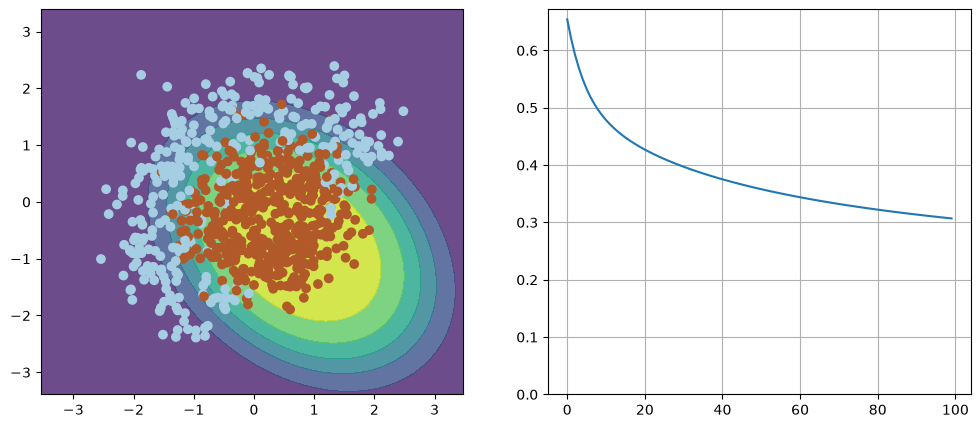

Loss: 0.307, точность: 0.915


<Figure size 640x480 with 0 Axes>

In [14]:
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1

n_iter = 100
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    grad = compute_grad(X_expanded, y, w)
    w = w - eta * grad
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['Full GD'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы полного градиентного спуска

С тем же `eta = 0.1` полный градиент даёт loss 0.31, почти как mini-batch SGD (0.30), только график абсолютно гладкий. При этом каждый шаг считается по всем 826 точкам, а у SGD по 4. На такой задаче батч из 4 точек почти не проигрывает полному градиенту.

## Nesterov Momentum

Отличие от Momentum в том, что градиент считается не в текущей точке, а там, куда нас и так унесёт накопленная скорость:

$$ \nu_t = \alpha \nu_{t-1} + \eta \nabla_w L(w_{t-1} - \alpha \nu_{t-1}) $$
$$ w_t = w_{t-1} - \nu_t $$

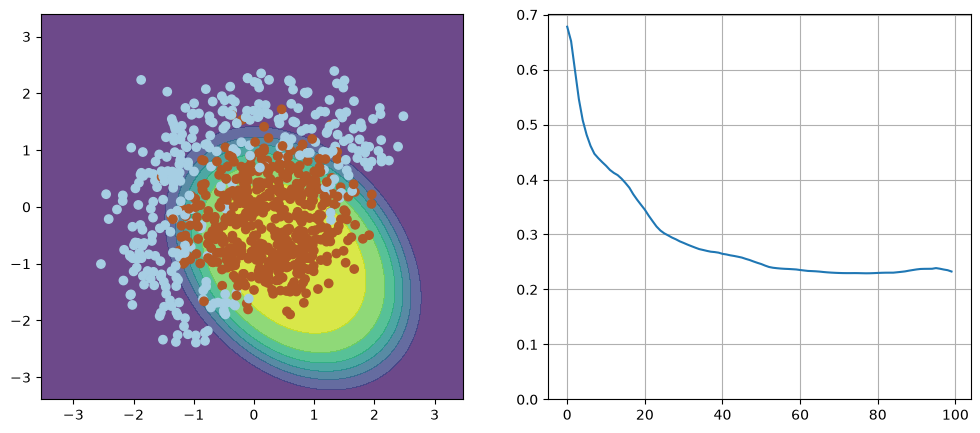

Loss: 0.233, точность: 0.903


<Figure size 640x480 with 0 Axes>

In [15]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.05
alpha = 0.9
nu = np.zeros_like(w)

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w - alpha * nu)
    nu = alpha * nu + eta * grad
    w = w - nu
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['Nesterov'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы Nesterov Momentum

Результат почти как у обычного Momentum (0.23). На такой простой задаче заглядывание вперёд почти ничего не даёт.

## AdaGrad

Как RMSprop, только квадраты градиентов не забываются, а копятся за всё время:

$$ G_t^j = G_{t-1}^j + g_{tj}^2 $$
$$ w_t^j = w_{t-1}^j - \dfrac{\eta}{\sqrt{G_t^j + \varepsilon}} g_{tj} $$

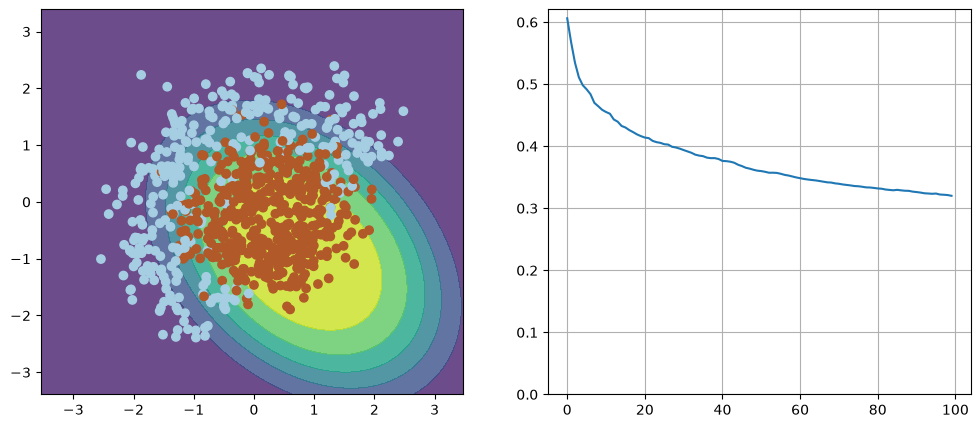

Loss: 0.320, точность: 0.914


<Figure size 640x480 with 0 Axes>

In [16]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1
G = np.zeros_like(w)
eps = 1e-8

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    G = G + grad ** 2
    w = w - eta / np.sqrt(G + eps) * grad
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['AdaGrad'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы AdaGrad

С тем же `eta = 0.1`, что у RMSprop, AdaGrad даёт loss 0.32, хуже даже SGD. Сумма $G$ только растёт, поэтому шаг всё время уменьшается и к концу обучение почти останавливается. Именно это исправляет RMSprop, который забывает старые градиенты.

## Adam

$$ m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \qquad v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 $$
$$ \hat m_t = \dfrac{m_t}{1 - \beta_1^t} \qquad \hat v_t = \dfrac{v_t}{1 - \beta_2^t} \qquad w_t = w_{t-1} - \dfrac{\eta \, \hat m_t}{\sqrt{\hat v_t} + \varepsilon} $$

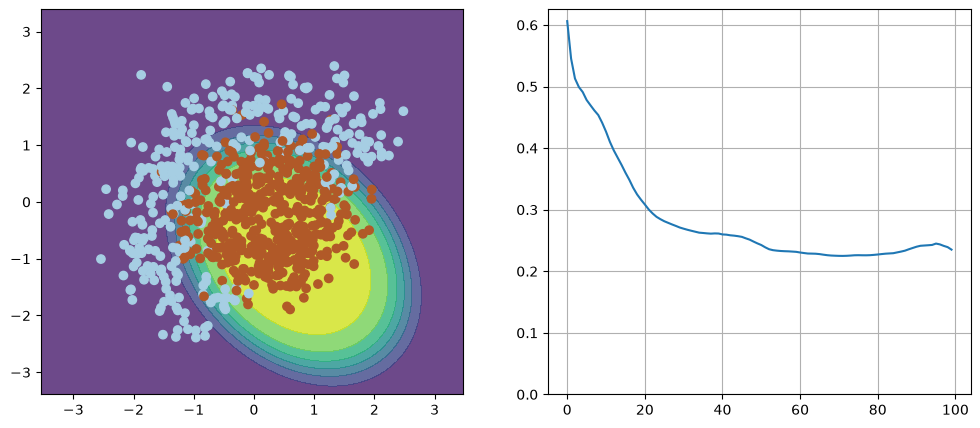

Loss: 0.235, точность: 0.901


<Figure size 640x480 with 0 Axes>

In [17]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1
beta1 = 0.9
beta2 = 0.999
m_t = np.zeros_like(w)
v_t = np.zeros_like(w)
eps = 1e-8

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    m_t = beta1 * m_t + (1 - beta1) * grad
    v_t = beta2 * v_t + (1 - beta2) * grad ** 2
    m_hat = m_t / (1 - beta1 ** (i + 1))
    v_hat = v_t / (1 - beta2 ** (i + 1))
    w = w - eta * m_hat / (np.sqrt(v_hat) + eps)
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['Adam'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы Adam

Adam даёт loss 0.24, на уровне Momentum и RMSprop. Выигрыша здесь нет: задача простая, и уже Momentum или RMSprop по отдельности справляются.

## AMSGrad

Adam, у которого в знаменателе берётся максимум из всех прошлых $v_t$. Так шаг не может резко вырасти, если градиенты вдруг стали маленькими:

$$ v^{max}_t = \max(v^{max}_{t-1}, v_t) \qquad w_t = w_{t-1} - \dfrac{\eta \, \hat m_t}{\sqrt{\hat v^{max}_t} + \varepsilon} $$

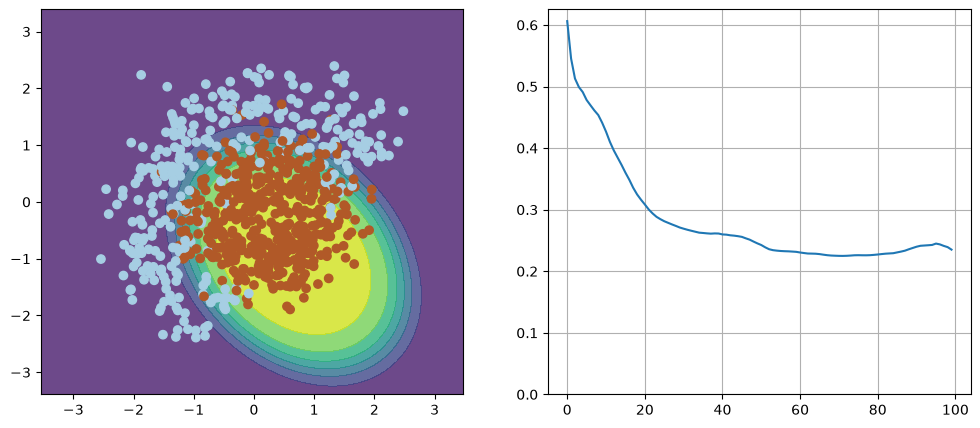

Loss: 0.235, точность: 0.901


<Figure size 640x480 with 0 Axes>

In [18]:
np.random.seed(42)
w = np.array([0, 0, 0, 0, 0, 1.])
eta = 0.1
beta1 = 0.9
beta2 = 0.999
m_t = np.zeros_like(w)
v_t = np.zeros_like(w)
v_max = np.zeros_like(w)
eps = 1e-8

n_iter = 100
batch_size = 4
loss = np.zeros(n_iter)
plt.figure(figsize=(12, 5))

for i in range(n_iter):
    ind = np.random.choice(X.shape[0], batch_size)
    grad = compute_grad(X_expanded[ind], y[ind], w)
    m_t = beta1 * m_t + (1 - beta1) * grad
    v_t = beta2 * v_t + (1 - beta2) * grad ** 2
    v_max = np.maximum(v_max, v_t)
    m_hat = m_t / (1 - beta1 ** (i + 1))
    v_hat = v_max / (1 - beta2 ** (i + 1))
    w = w - eta * m_hat / (np.sqrt(v_hat) + eps)
    loss[i] = compute_loss(X_expanded, y, w)

visualize(X, y, w, loss)
plt.clf()

results['AMSGrad'] = loss
print(f'Loss: {loss[-1]:.3f}, точность: {accuracy(w):.3f}')

## Вывод работы AMSGrad

Результат как у Adam (0.235): на этой задаче ограничение шага ни на что не повлияло.

## Технический отчёт

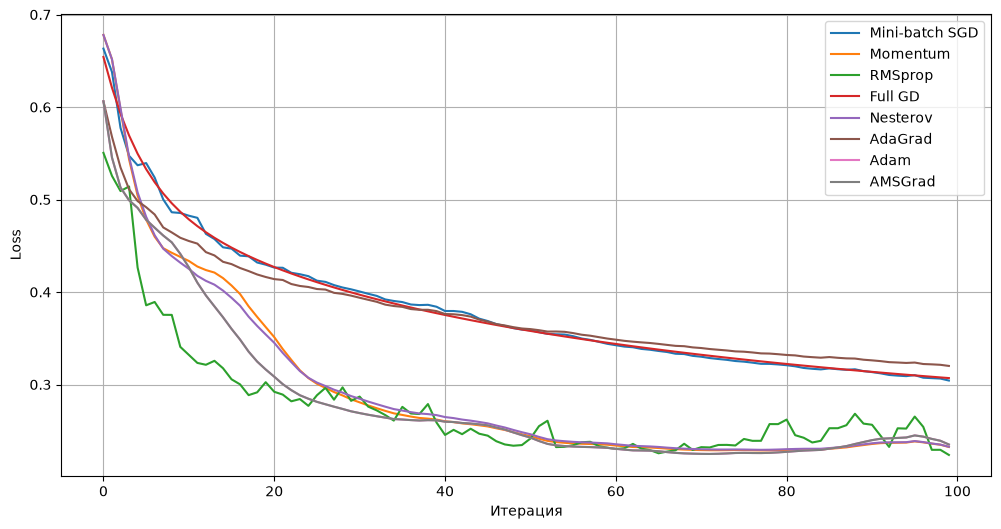

In [19]:
plt.figure(figsize=(12, 6))
for name, history in results.items():
    plt.plot(history, label=name)
plt.xlabel('Итерация')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

| Метод | `eta` | Loss после 100 итераций |
|---|---|---|
| Mini-batch SGD (baseline) | 0.1 | 0.30 |
| Momentum SGD | 0.05 | 0.23 |
| RMSprop | 0.1 | 0.22 |
| Полный градиентный спуск | 0.1 | 0.31 |
| Nesterov Momentum | 0.05 | 0.23 |
| AdaGrad | 0.1 | 0.32 |
| Adam | 0.1 | 0.24 |
| AMSGrad | 0.1 | 0.24 |

Baseline — обычный mini-batch SGD. Перебить его получилось двумя способами: накапливать направление движения (Momentum, Nesterov) или подбирать шаг для каждого веса (RMSprop). Adam и AMSGrad объединяют оба подхода, но на этой задаче лучше них не стали. Полный градиентный спуск с тем же шагом даёт почти тот же loss, что и SGD, то есть дело не в размере батча. AdaGrad оказался хуже baseline, потому что его шаг со временем затухает.

Точность у всех методов примерно одинаковая, около 0.90–0.92: граница-окружность находится быстро, а методы отличаются тем, насколько быстро и ровно падает loss.